# Day 3 lab: Applied Lab 4 — Forecasting

<p class="lead">
Forecast atmospheric CO₂ the way a professional would: test whether the series is stationary, hide the most recent fifth of the data, fit a seasonal ARIMA model to the rest, forecast the hidden period, and prove the model's accuracy with RMSE and MAE before anyone relies on it.
</p>

*Adapted from the DATA 300 syllabus, Applied Lab 4 (Forecasting), for local Jupyter without internet access.*

| | |
|---|---|
| **Graded** | Yes: **3%** of the course grade |
| **Outcomes** | CLO 1, 2 and 5 |
| **Tool** | JupyterLab (Anaconda), with statsmodels and scikit-learn |
| **You submit** | One PDF, `YourLastName_DATA300_AppliedLab4.pdf`, in the **Applied Lab 4** drop-box on **GAP (Moodle)** |
| **Deadline** | Thursday 12 November, 23:59 China Standard Time, unless your facilitator says otherwise (see the [schedule](schedule.md)) |

---

## The business scenario

You are a data scientist at **Global Climate Analytics**. You have been asked to predict future levels of carbon dioxide (CO₂) in the atmosphere from the long record measured at the **Mauna Loa Observatory** in Hawaii. Concentrations are in **parts per million (ppm)**.

Your forecast will be presented to environmental policymakers, so you must first **show** that it is accurate. You cannot do that by forecasting the unknown future. Instead you hold back the most recent part of the history, let the model forecast those months without seeing them, and compare its forecasts with what was actually measured.

Your tasks:

1. **Stationarity:** test the series with the Augmented Dickey-Fuller (ADF) test.
2. **Train/test split:** divide the series in time order into a training set (the first 80%) and a test set (the last 20%).
3. **Model and evaluate:** fit a Seasonal ARIMA (SARIMA) model on the training set only, forecast the test period, and measure the error with RMSE and MAE.

This is **predictive** analytics, judged by the standards a business intelligence team would apply before a forecast supports a decision.

### Before you start

1. Keep this notebook in the course folder.
2. Save your own copy: **File → Save Notebook As…** and type `YourLastName_Data300_AppliedLab4.ipynb` (with your real last name). Work in that copy.
3. The code below works as given. Run each cell in order with **Shift + Enter**, read the output, and answer the questions in Part 4. You may add cells of your own to check an answer.

---

## Part 1: Load the data and test for stationarity

The CO₂ data ship inside `statsmodels`, so they load without internet. The raw series is **weekly** with some missing weeks; the cell averages it to **monthly** values and fills any month without a measurement with the value of the month before.

ARIMA models assume the series is **stationary**: its average and spread do not drift over time. The **ADF test** checks this. Its null hypothesis is that the series is *not* stationary:

| ADF p-value | Conclusion |
|---|---|
| p > 0.05 | Not enough evidence of stationarity: the series has a trend and must be differenced |
| p ≤ 0.05 | The series can be treated as stationary |

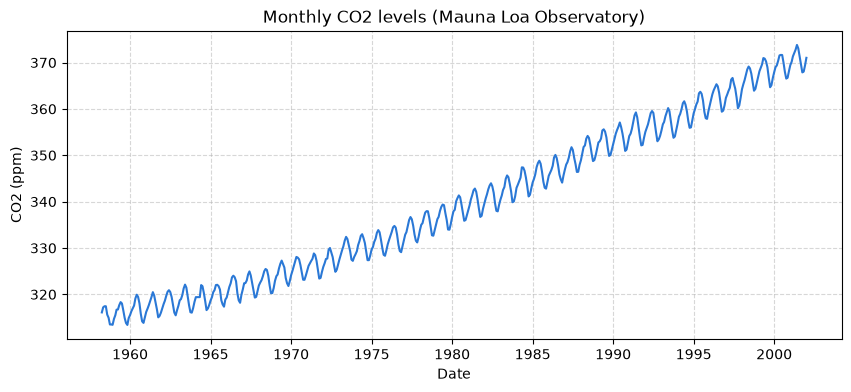

--- Augmented Dickey-Fuller (ADF) test results ---
ADF statistic: 2.2848
p-value: 0.9989
Conclusion: the p-value is above 0.05. The series is NOT stationary (it has a trend).


In [1]:
# 1. Libraries
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.metrics import mean_absolute_error, mean_squared_error
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore")   # hide notices about future library changes and fitting messages

# 2. Load the CO2 series that ships with statsmodels
dataset = sm.datasets.co2.load_pandas()
df = dataset.data

# 3. Weekly to monthly averages ("ME" = month end); fill months with no measurement
df = df.resample("ME").mean().ffill()

# 4. Plot the monthly series
plt.figure(figsize=(10, 4))
plt.plot(df.index, df["co2"], color="#2a78d6")
plt.title("Monthly CO2 levels (Mauna Loa Observatory)")
plt.ylabel("CO2 (ppm)")
plt.xlabel("Date")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# 5. Stationarity test: Augmented Dickey-Fuller (ADF)
print("--- Augmented Dickey-Fuller (ADF) test results ---")
adf_result = adfuller(df["co2"])
print(f"ADF statistic: {adf_result[0]:.4f}")
print(f"p-value: {adf_result[1]:.4f}")
if adf_result[1] > 0.05:
    print("Conclusion: the p-value is above 0.05. The series is NOT stationary (it has a trend).")
else:
    print("Conclusion: the p-value is 0.05 or below. The series IS stationary.")

Use this output for question 1.

---

## Part 2: Train/test split in time order

A time series must be split **in time order**, never at random: the model learns from the earlier **training** set (the first 80% of months) and is judged on the later **test** set (the last 20%), which it never sees during fitting. This is how a forecast is used in real life: the past predicts the future.

Total observations: 526 months
Training period: 420 months (Mar 1958 to Feb 1993)
Test period: 106 months (Mar 1993 to Dec 2001)


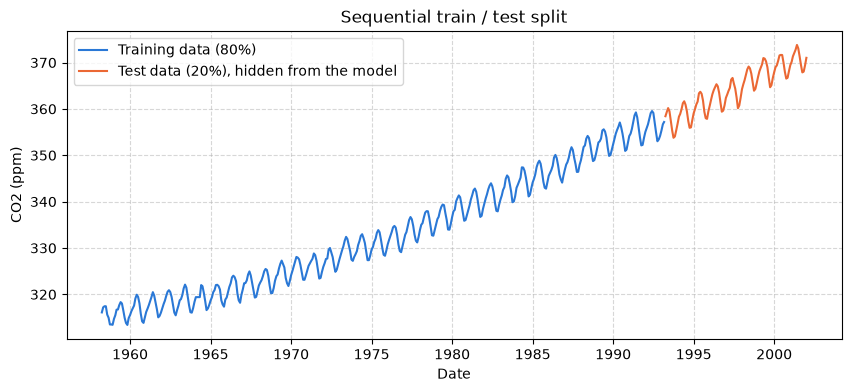

In [2]:
# 1. Sequential split: first 80% for training, last 20% for testing
train_size = int(len(df) * 0.8)
train_data, test_data = df.iloc[:train_size], df.iloc[train_size:]

print(f"Total observations: {len(df)} months")
print(f"Training period: {len(train_data)} months ({train_data.index[0]:%b %Y} to {train_data.index[-1]:%b %Y})")
print(f"Test period: {len(test_data)} months ({test_data.index[0]:%b %Y} to {test_data.index[-1]:%b %Y})")

# 2. Show the split
plt.figure(figsize=(10, 4))
plt.plot(train_data.index, train_data["co2"], label="Training data (80%)", color="#2a78d6")
plt.plot(test_data.index, test_data["co2"], label="Test data (20%), hidden from the model", color="#eb6834")
plt.title("Sequential train / test split")
plt.ylabel("CO2 (ppm)")
plt.xlabel("Date")
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

---

## Part 3: SARIMA model and accuracy

The series has a long upward **trend** and a strong **12-month seasonal** pattern, so we fit a **Seasonal ARIMA** model, written SARIMA(p, d, q) × (P, D, Q)ₛ:

| Part | Values here | Meaning |
|---|---|---|
| (p, d, q) | (1, 1, 1) | One autoregressive term, **one difference** to remove the trend, one moving-average error term |
| (P, D, Q, s) | (1, 1, 1, 12) | The same three ideas at the seasonal lag of 12 months |

The model is fitted on the **training data only**. It then forecasts every month of the test period, and two measures compare the forecasts with the actual values:

| Measure | Meaning |
|---|---|
| **MAE**, mean absolute error | The average size of the miss, in ppm |
| **RMSE**, root mean squared error | Like MAE, but large misses count more; always at least as large as MAE |

Fitting can take 10–20 seconds.

Fitting the SARIMA model (this may take 10-20 seconds)...

--- Out-of-sample accuracy on the test period ---
Root mean squared error (RMSE): 2.13 ppm
Mean absolute error (MAE): 1.81 ppm


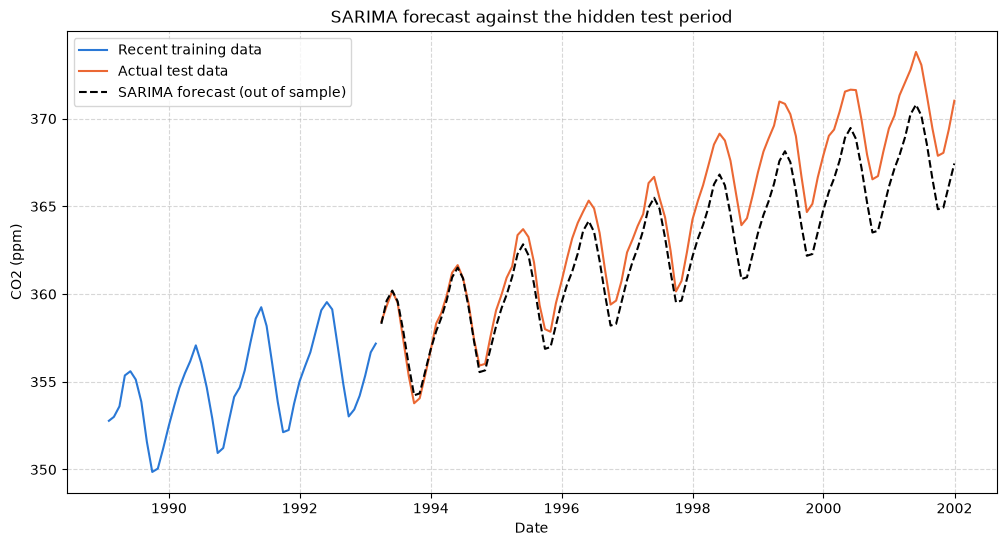

In [3]:
# 1. Fit the SARIMA model on the TRAINING data only
print("Fitting the SARIMA model (this may take 10-20 seconds)...")
model = sm.tsa.statespace.SARIMAX(
    train_data["co2"],
    order=(1, 1, 1),
    seasonal_order=(1, 1, 1, 12),
)
sarima_result = model.fit(disp=False)

# 2. Forecast every month of the TEST period
forecast_steps = len(test_data)
predictions = sarima_result.get_forecast(steps=forecast_steps)
pred_mean = predictions.predicted_mean

# 3. Accuracy on the hidden test period
rmse = np.sqrt(mean_squared_error(test_data["co2"], pred_mean))
mae = mean_absolute_error(test_data["co2"], pred_mean)
print("\n--- Out-of-sample accuracy on the test period ---")
print(f"Root mean squared error (RMSE): {rmse:.2f} ppm")
print(f"Mean absolute error (MAE): {mae:.2f} ppm")

# 4. Compare the forecast with what actually happened
plt.figure(figsize=(12, 6))
plt.plot(train_data.index[-50:], train_data["co2"][-50:], label="Recent training data", color="#2a78d6")
plt.plot(test_data.index, test_data["co2"], label="Actual test data", color="#eb6834")
plt.plot(test_data.index, pred_mean, label="SARIMA forecast (out of sample)", color="black", linestyle="--")
plt.title("SARIMA forecast against the hidden test period")
plt.ylabel("CO2 (ppm)")
plt.xlabel("Date")
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

Use the error measures and the chart above for questions 3 and 4. In the chart, the **black dashed line** is the model's forecast and the **solid orange line** is what was actually measured.

---

## Part 4: Questions

Answer **all four questions in complete sentences** in the answer cell below. Base every answer on the outputs in this notebook, and quote the numbers you use.

| # | Question |
|---|---|
| **1** | **Stationarity and differencing.** (a) What exact p-value did the ADF test in Part 1 give? (b) Using that p-value, explain why the model differences the series once (the non-seasonal setting d = 1) instead of fitting an ARMA model to the undifferenced series. |
| **2** | **Why hold back a test period?** Part 2 kept the last 20% of the history away from the model while it was fitted. In a real consulting project, why is this time-ordered train/test check much stronger evidence than fitting the model to 100% of the history? Name the risk it protects against. |
| **3** | **Judging the error.** (a) State the MAE you obtained in Part 3. (b) CO₂ concentrations in this data are roughly 350 ppm or more. Is this error **excellent**, **acceptable** or **poor**? Justify your judgement, for example by expressing the error as a percentage of the level, or by comparing it with the size of the yearly seasonal swing visible in the charts. |
| **4** | **Reading the forecast chart.** In the final chart of Part 3, did the SARIMA forecast reproduce (a) the overall upward direction and (b) the repeating yearly up-and-down pattern of CO₂? Describe any systematic gap you see between the dashed and the solid line. |

> **Writing tips**
>
> Lead with the answer, then the evidence: *"The ADF p-value of … is well above 0.05, so …"*. Keep units (ppm, months). For question 3, a policymaker should be able to understand your judgement without knowing what RMSE means.

> **My answers**
>
> **Name:** *Your name* · **Student ID:** *Your ID*
>
> **1. (a) ADF p-value:** *Your answer*
>
> **1. (b) Why difference once (d = 1):** *Your answer*
>
> **2. Why a time-ordered train/test check, and the risk it reduces:** *Your answer*
>
> **3. (a) MAE:** *Your answer*
>
> **3. (b) Excellent, acceptable or poor, and why:** *Your answer*
>
> **4. Trend, seasonal pattern and any systematic gap:** *Your answer*

---

## Going further (not graded)

Two checks a careful analyst adds. First, a **baseline**: the *seasonal naive* forecast simply repeats the value from the same month one year earlier. A model is only worth its complexity if it beats this. Second, a **95% forecast interval**: the range the model expects the actual values to fall in. The cell below computes both for the same test period.

                         MAE (ppm)  RMSE (ppm)
SARIMA                        1.81        2.13
Seasonal naive baseline       7.93        9.13

Share of test months inside the 95% interval: 100%


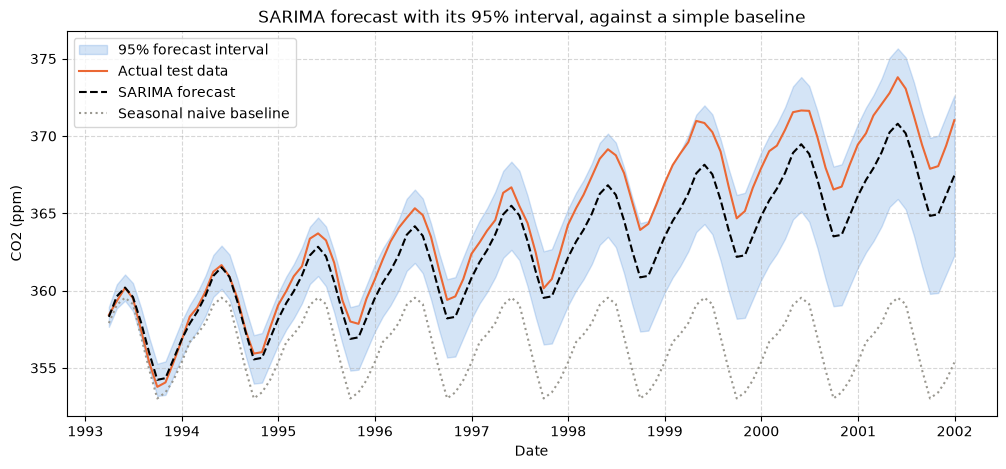

In [4]:
# Seasonal naive baseline: each test month gets the value from 12 months earlier
# (for test months beyond the first year, that value is itself the earlier forecast)
history = list(train_data["co2"])
naive = []
for _ in range(len(test_data)):
    naive.append(history[-12])
    history.append(history[-12])
naive = pd.Series(naive, index=test_data.index)

baseline = pd.DataFrame({
    "MAE (ppm)": [mean_absolute_error(test_data["co2"], pred_mean), mean_absolute_error(test_data["co2"], naive)],
    "RMSE (ppm)": [np.sqrt(mean_squared_error(test_data["co2"], pred_mean)),
                   np.sqrt(mean_squared_error(test_data["co2"], naive))],
}, index=["SARIMA", "Seasonal naive baseline"])
print(baseline.round(2).to_string())

# 95% forecast interval from the SARIMA model
interval = predictions.conf_int(alpha=0.05)
inside = ((test_data["co2"] >= interval.iloc[:, 0]) & (test_data["co2"] <= interval.iloc[:, 1])).mean()
print(f"\nShare of test months inside the 95% interval: {inside:.0%}")

plt.figure(figsize=(12, 5))
plt.fill_between(test_data.index, interval.iloc[:, 0], interval.iloc[:, 1], color="#2a78d6", alpha=0.2,
                 label="95% forecast interval")
plt.plot(test_data.index, test_data["co2"], label="Actual test data", color="#eb6834")
plt.plot(test_data.index, pred_mean, label="SARIMA forecast", color="black", linestyle="--")
plt.plot(test_data.index, naive, label="Seasonal naive baseline", color="#9a9890", linestyle=":")
plt.title("SARIMA forecast with its 95% interval, against a simple baseline")
plt.ylabel("CO2 (ppm)")
plt.xlabel("Date")
plt.legend(loc="upper left")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

Does SARIMA beat the baseline, and by how much? Why does the interval widen towards the end of the test period? Do the actual values stay inside it, or drift towards one edge, and what does that suggest about the trend in the 1990s?

---

## Part 5: Export and submit

### 1. Export to PDF

1. Choose **Kernel → Restart Kernel and Run All Cells**. Check that the CO₂ chart, the ADF results, the split chart, the error measures and the forecast chart all appear, and that your answers are in the answer cell.
2. Choose **File → Print** (or Ctrl + P / Cmd + P).
3. Set the destination to **Save as PDF**. Under *More settings*, tick **Background graphics** so the line colours are kept.
4. Save the file as **`YourLastName_DATA300_AppliedLab4.pdf`**, with your real last name.

Your answers are inside the notebook, so this one PDF is the whole submission. If you wrote any answers in a separate document, combine the PDFs into one file without internet, as shown in [Combining PDFs without internet](setup.md#combining-pdfs-without-internet).

### 2. Upload

Log in to **GAP (Moodle)**, open the **DATA 300: Applied Lab 4** drop-box, upload the PDF and click **Submit**.

---

## Checklist before you upload

- [ ] The notebook was **restarted and run all**; the ADF results, the split sizes and the RMSE and MAE all appear.
- [ ] All three charts appear, in colour.
- [ ] All four questions are answered in complete sentences, with the numbers you used.
- [ ] Your name and student ID are in the answer cell.
- [ ] The file is named `YourLastName_DATA300_AppliedLab4.pdf` and uploaded to the Applied Lab 4 drop-box on GAP (Moodle).

## How it is marked

The lab uses the course's Lab 4 rubric: **CLO 1** (describing descriptive, predictive and prescriptive analytics for a business problem, 25 points), **CLO 2** (using visualisation and modelling tools to communicate findings, 25 points), **CLO 5** (evaluating how an analytical model supports managerial decisions, 30 points), **professional formatting** (10 points) and **clear academic writing** (10 points). In practice: all outputs present, correct values quoted, a reasoned judgement of the error, and a correctly named PDF.

> **Stuck?**
>
> `ValueError: Invalid frequency: ME` means your pandas is older than version 2.2: change `"ME"` to `"M"` in Part 1 and run again. `ModuleNotFoundError` for `statsmodels` or `sklearn`: run the [setup check](00_setup_check.md) and follow its fix. For anything else, take a screenshot and ask your facilitator.